**1. Descriptive statistics: mean, median, mode and variance**

In [ ]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
clean_data = pd.read_csv("ontario_school_boards_clean.csv")
print("Shape:", clean_data.shape)
clean_data.head()

Saving ontario_school_boards_clean.csv to ontario_school_boards_clean (1).csv
Shape: (79, 16)


,Board Number,Board_Name,Board_Language,Board Type,Region,City,Grade 10 OSSLT Results,Progress in Grade 10 OSSLT Results,Credit Accumulation by the end of Grade 10,Progress in Credit Accumulation by the end of Grade 10,Credit Accumulation by the end of Grade 11,Progress in Credit Accumulation by the end of Grade 11,Four Year Graduation Rate 2020-2021 Grade 9 Cohort,Progress in Four Year Graduation Rate 2020-2021 Grade 9 Cohort,FiveYear_Graduation,Progress in Five Year Graduation Rate 2019-2020 Grade 9 Cohort
0,B28010,Algoma DSB,English,Public,North Region,Sault Ste Marie,0.73,0.01,0.72,0.02,0.77,0.02,0.738,0.029,0.775,0.015
1,B67202,Algonquin and Lakeshore CDSB,English,Roman Catholic,East Region,Napanee,0.86,0.00,0.84,0.03,0.88,0.01,0.914,0.032,0.926,0.003
2,B66010,Avon Maitland DSB,English,Public,West Region,Seaforth,0.81,0.00,0.79,0.03,0.78,0.01,0.784,-0.022,0.861,-0.007
3,B66001,Bluewater DSB,English,Public,West Region,Chesley,0.82,0.07,0.70,0.06,0.70,0.01,0.725,0.024,0.852,0.028
4,B67164,Brant Haldimand Norfolk CDSB,English,Roman Catholic,West Region,Brantford,0.89,0.04,0.80,0.04,0.85,0.04,0.841,-0.015,0.873,0.005


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

numeric_columns = [
    "Grade10_OSSLT",
    "Grade10_Credits",
    "Grade11_Credits",
    "FiveYear_Graduation"
]

analysis_data = clean_data.copy()

for col in numeric_columns:
    analysis_data[col] = (
        analysis_data[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.replace("\xa0", "", regex=False)
        .str.strip()
    )

    analysis_data[col] = pd.to_numeric(
        analysis_data[col],
        errors="coerce"
    )

print("Number of observations:", len(analysis_data))
print("\nMissing values:")
print(analysis_data[numeric_columns].isna().sum())

Number of observations: 70

Missing values:
Grade10_OSSLT          0
Grade10_Credits        0
Grade11_Credits        0
FiveYear_Graduation    0
dtype: int64


In [ ]:
desc_data = analysis_data[numeric_columns].copy()

for col in numeric_columns:
    if desc_data[col].max() <= 1:
        desc_data[col] = desc_data[col] * 100

summary = pd.DataFrame({
    "Mean": desc_data.mean(),
    "Median": desc_data.median(),
    "Mode": desc_data.mode().iloc[0],
    "Variance": desc_data.var(),
    "Std. Deviation": desc_data.std(),
    "Minimum": desc_data.min(),
    "Maximum": desc_data.max()
})

summary.round(2)

,Mean,Median,Mode,Variance,Std. Deviation,Minimum,Maximum
Grade10_OSSLT,84.00,84.5,81.0,45.65,6.76,57.0,97.0
Grade10_Credits,80.73,81.0,81.0,56.72,7.53,63.0,95.0
Grade11_Credits,83.10,84.5,85.0,50.24,7.09,65.0,95.0
FiveYear_Graduation,87.53,88.3,77.5,38.14,6.18,69.0,97.4


In [ ]:
for col in numeric_columns:
    print(f"\n{col} mode(s):")
    print(desc_data[col].mode().tolist())


Grade10_OSSLT mode(s):
[81.0]

Grade10_Credits mode(s):
[81.0, 84.0]

Grade11_Credits mode(s):
[85.0]

FiveYear_Graduation mode(s):
[77.5, 86.1, 87.4, 87.5, 88.3, 89.0, 91.2, 92.4, 94.1]


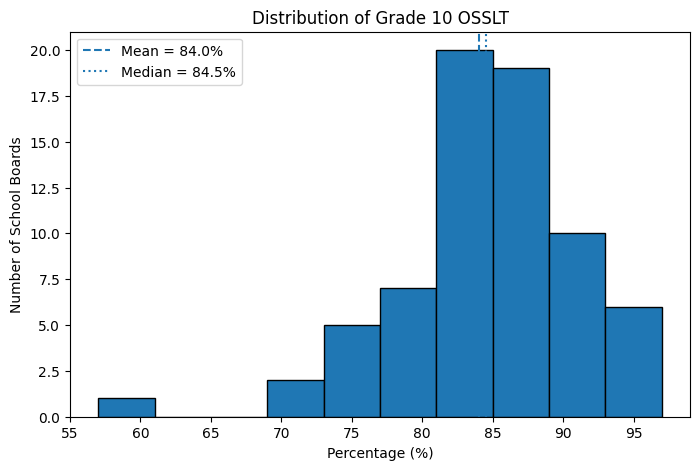

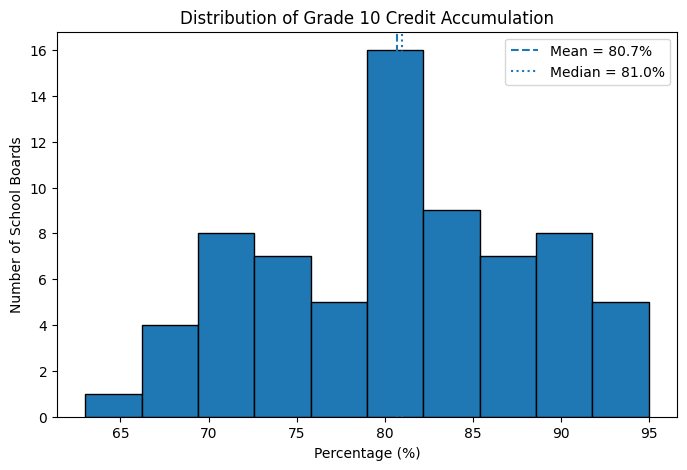

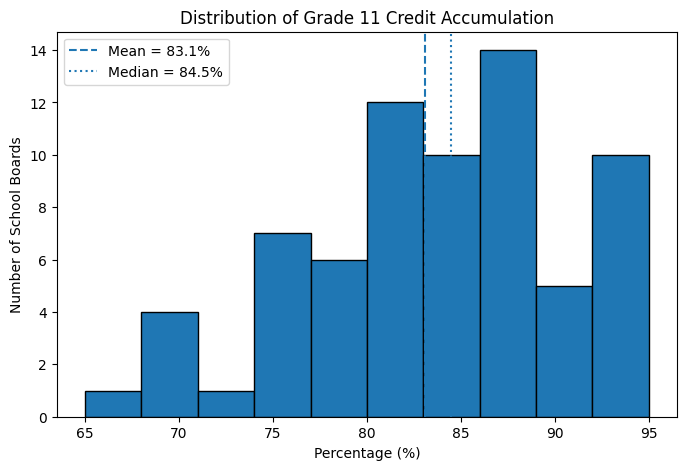

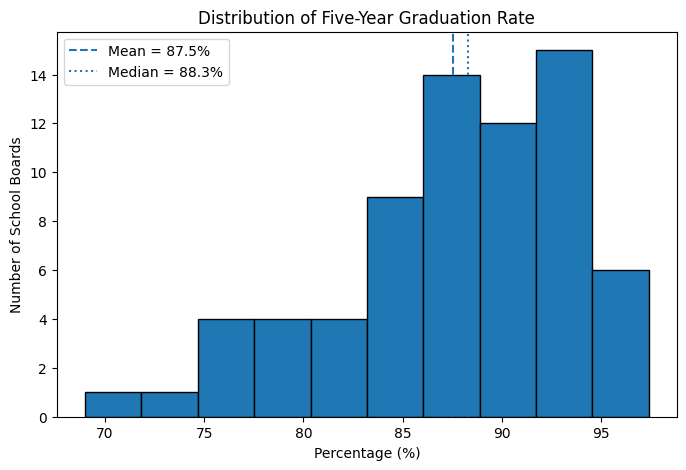

In [ ]:
plot_names = {
    "Grade10_OSSLT": "Grade 10 OSSLT",
    "Grade10_Credits": "Grade 10 Credit Accumulation",
    "Grade11_Credits": "Grade 11 Credit Accumulation",
    "FiveYear_Graduation": "Five-Year Graduation Rate"
}

for col in numeric_columns:

    plt.figure(figsize=(8, 5))

    plt.hist(
        desc_data[col].dropna(),
        bins=10,
        edgecolor="black"
    )

    plt.axvline(
        desc_data[col].mean(),
        linestyle="--",
        label=f"Mean = {desc_data[col].mean():.1f}%"
    )

    plt.axvline(
        desc_data[col].median(),
        linestyle=":",
        label=f"Median = {desc_data[col].median():.1f}%"
    )

    plt.title(f"Distribution of {plot_names[col]}")
    plt.xlabel("Percentage (%)")
    plt.ylabel("Number of School Boards")
    plt.legend()

    plt.show()

In [ ]:
skewness = desc_data.skew().to_frame(name="Skewness")
skewness.round(2)

,Skewness
Grade10_OSSLT,-1.01
Grade10_Credits,-0.16
Grade11_Credits,-0.39
FiveYear_Graduation,-0.78


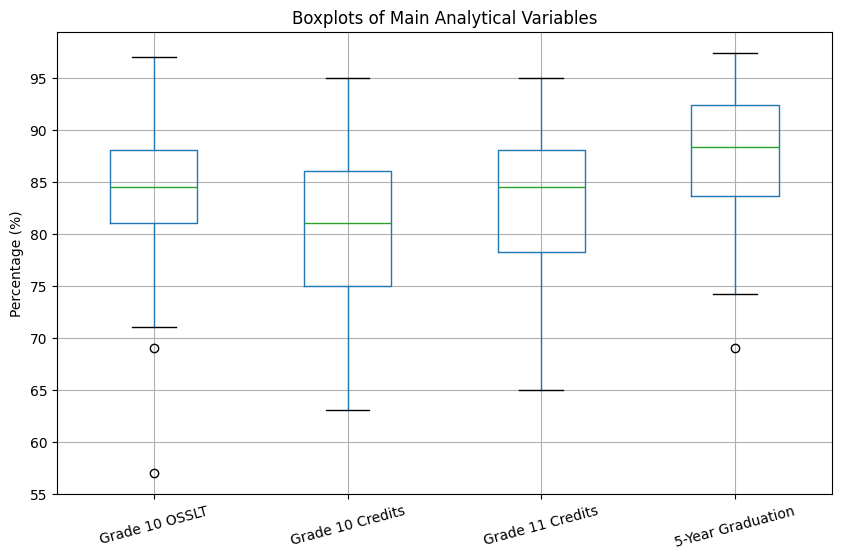

In [ ]:
boxplot_data = desc_data.rename(columns={
    "Grade10_OSSLT": "Grade 10 OSSLT",
    "Grade10_Credits": "Grade 10 Credits",
    "Grade11_Credits": "Grade 11 Credits",
    "FiveYear_Graduation": "5-Year Graduation"
})

plt.figure(figsize=(10, 6))

boxplot_data.boxplot(
    column=list(boxplot_data.columns)
)

plt.title("Boxplots of Main Analytical Variables")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15)

plt.show()

In [ ]:
for col in numeric_columns:

    Q1 = desc_data[col].quantile(0.25)
    Q3 = desc_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (desc_data[col] < lower_bound) |
        (desc_data[col] > upper_bound)
    )

    print(f"\n{plot_names[col]}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))

    if outlier_mask.sum() == 0:
        print("No IQR outliers.")
    else:
        print("Number of potential outliers:", outlier_mask.sum())

        if "Board_Name" in analysis_data.columns:
            result = analysis_data.loc[outlier_mask, ["Board_Name"]].copy()
            result["Value (%)"] = desc_data.loc[outlier_mask, col]
            print(result)
        else:
            print(desc_data.loc[outlier_mask, col])


Grade 10 OSSLT
Lower bound: 70.5
Upper bound: 98.5
Number of potential outliers: 2
                 Board_Name  Value (%)
49          Rainy River DSB       69.0
56  Superior-Greenstone DSB       57.0

Grade 10 Credit Accumulation
Lower bound: 58.5
Upper bound: 102.5
No IQR outliers.

Grade 11 Credit Accumulation
Lower bound: 63.62
Upper bound: 102.62
No IQR outliers.

Five-Year Graduation Rate
Lower bound: 70.44
Upper bound: 105.54
Number of potential outliers: 1
               Board_Name  Value (%)
34  Keewatin-Patricia DSB       69.0


In [ ]:
correlation_matrix = desc_data.corr()

correlation_matrix.round(3)

,Grade10_OSSLT,Grade10_Credits,Grade11_Credits,FiveYear_Graduation
Grade10_OSSLT,1.000,0.647,0.713,0.745
Grade10_Credits,0.647,1.000,0.838,0.728
Grade11_Credits,0.713,0.838,1.000,0.845
FiveYear_Graduation,0.745,0.728,0.845,1.000


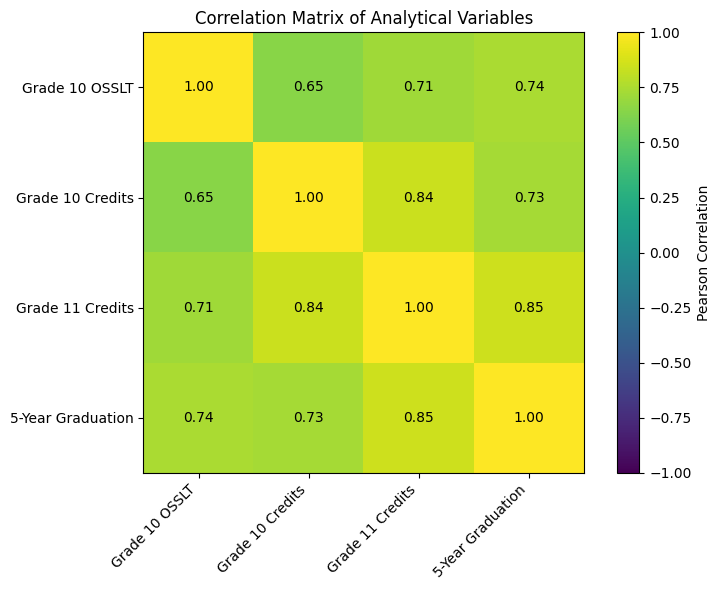

In [ ]:
labels = [
    "Grade 10 OSSLT",
    "Grade 10 Credits",
    "Grade 11 Credits",
    "5-Year Graduation"
]

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(labels)),
    labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(labels)),
    labels
)

for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Analytical Variables")
plt.tight_layout()
plt.show()

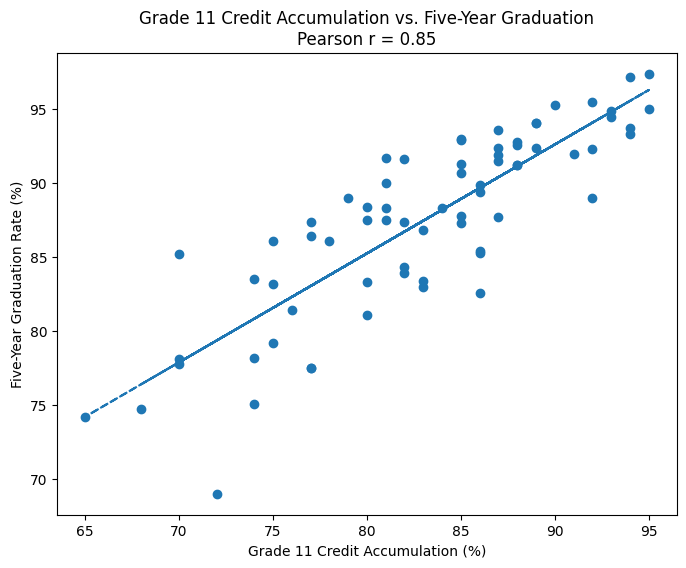

In [ ]:
x = desc_data["Grade11_Credits"]
y = desc_data["FiveYear_Graduation"]

plt.figure(figsize=(8, 6))

plt.scatter(x, y)

slope, intercept = np.polyfit(x, y, 1)

plt.plot(
    x,
    slope * x + intercept,
    linestyle="--"
)

r = x.corr(y)

plt.title(
    f"Grade 11 Credit Accumulation vs. Five-Year Graduation\n"
    f"Pearson r = {r:.2f}"
)

plt.xlabel("Grade 11 Credit Accumulation (%)")
plt.ylabel("Five-Year Graduation Rate (%)")

plt.show()

In [ ]:
if analysis_data["FiveYear_Graduation"].max() <= 1:
    provincial_benchmark = 0.895
else:
    provincial_benchmark = 89.5

analysis_data["Below_Benchmark"] = (
    analysis_data["FiveYear_Graduation"] < provincial_benchmark
).astype(int)

print(
    analysis_data["Below_Benchmark"]
    .value_counts()
    .sort_index()
)

print("\nPercentages:")

print(
    analysis_data["Below_Benchmark"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

Below_Benchmark
0    30
1    40
Name: count, dtype: int64

Percentages:
Below_Benchmark
0    42.857143
1    57.142857
Name: proportion, dtype: float64


In [ ]:
X = analysis_data[
    [
        "Grade10_OSSLT",
        "Grade10_Credits",
        "Grade11_Credits"
    ]
]

y = analysis_data["Below_Benchmark"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (70, 3)
Target shape: (70,)


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline_predictions = cross_val_predict(
    baseline,
    X,
    y,
    cv=cv
)

print("Baseline Accuracy:",
      round(accuracy_score(y, baseline_predictions), 3))

print("Baseline Precision:",
      round(precision_score(y, baseline_predictions), 3))

print("Baseline Recall:",
      round(recall_score(y, baseline_predictions), 3))

print("Baseline F1:",
      round(f1_score(y, baseline_predictions), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y, baseline_predictions))

Baseline Accuracy: 0.571
Baseline Precision: 0.571
Baseline Recall: 1.0
Baseline F1: 0.727

Confusion Matrix:
[[ 0 30]
 [ 0 40]]


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_predictions = cross_val_predict(
    logistic_model,
    X,
    y,
    cv=cv
)

print("Logistic Regression")

print("Accuracy:",
      round(accuracy_score(y, logistic_predictions), 3))

print("Precision:",
      round(precision_score(y, logistic_predictions), 3))

print("Recall:",
      round(recall_score(y, logistic_predictions), 3))

print("F1:",
      round(f1_score(y, logistic_predictions), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y, logistic_predictions))

Logistic Regression
Accuracy: 0.8
Precision: 0.81
Recall: 0.85
F1: 0.829

Confusion Matrix:
[[22  8]
 [ 6 34]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

tree_predictions = cross_val_predict(
    tree_model,
    X,
    y,
    cv=cv
)

print("Decision Tree")

print("Accuracy:",
      round(accuracy_score(y, tree_predictions), 3))

print("Precision:",
      round(precision_score(y, tree_predictions), 3))

print("Recall:",
      round(recall_score(y, tree_predictions), 3))

print("F1:",
      round(f1_score(y, tree_predictions), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y, tree_predictions))

Decision Tree
Accuracy: 0.686
Precision: 0.737
Recall: 0.7
F1: 0.718

Confusion Matrix:
[[20 10]
 [12 28]]


In [ ]:
def evaluate_predictions(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    specificity = tn / (tn + fp)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Specificity": specificity
    }


results = pd.DataFrame({
    "Majority Baseline":
        evaluate_predictions(y, baseline_predictions),

    "Logistic Regression":
        evaluate_predictions(y, logistic_predictions),

    "Decision Tree":
        evaluate_predictions(y, tree_predictions)
}).T

results.round(3)

,Accuracy,Precision,Recall,F1,Specificity
Majority Baseline,0.571,0.571,1.00,0.727,0.000
Logistic Regression,0.800,0.810,0.85,0.829,0.733
Decision Tree,0.686,0.737,0.70,0.718,0.667


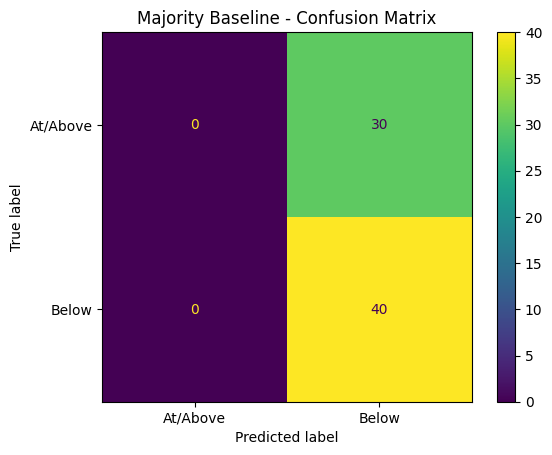

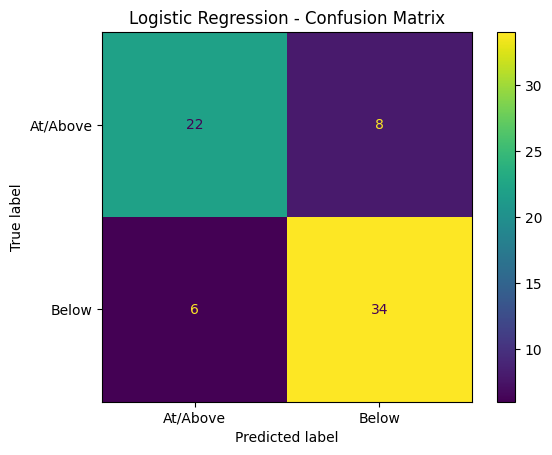

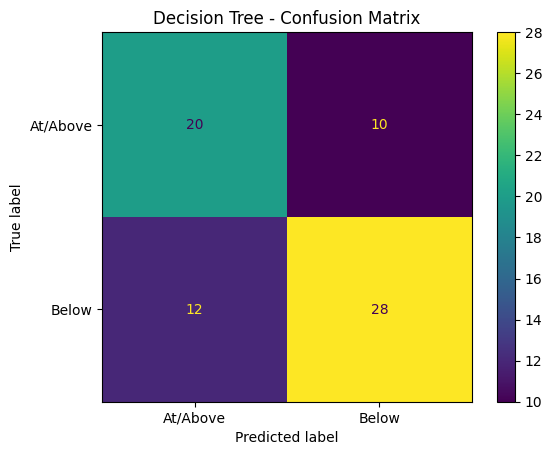

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

models_predictions = {
    "Majority Baseline": baseline_predictions,
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions
}

for name, predictions in models_predictions.items():

    ConfusionMatrixDisplay.from_predictions(
        y,
        predictions,
        display_labels=[
            "At/Above",
            "Below"
        ]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.show()